In [1]:
import pandas as pd
import sqlite3
con = sqlite3.connect("C:/Users/fathi/Downloads/ipl sem 3/IPL-Cricket-Analyticss/data/raw/ipl.db")
def q(sql):
    return pd.read_sql(sql,con)

### What is the impact of first-innings scores on the success rate of chasing teams?

In [4]:
chase_bands = q("""
WITH chase_data AS (
    SELECT
        first_innings_total,

        CASE
            WHEN first_innings_total < 140 THEN 'Under 140'
            WHEN first_innings_total BETWEEN 140 AND 159 THEN '140-159'
            WHEN first_innings_total BETWEEN 160 AND 179 THEN '160-179'
            WHEN first_innings_total BETWEEN 180 AND 199 THEN '180-199'
            ELSE '200+'
        END AS score_band,

        CASE
            WHEN match_winner != innings1_batting_team THEN 1
            ELSE 0
        END AS chase_win

    FROM v_match_totals
    WHERE result = 'win'
      AND first_innings_total IS NOT NULL
)

SELECT
    score_band,
    COUNT(*) AS sample_size,
    ROUND(
        100.0 * SUM(chase_win) / COUNT(*),
        1
    ) AS chase_win_rate
FROM chase_data
GROUP BY score_band
ORDER BY
    CASE score_band
        WHEN 'Under 140' THEN 1
        WHEN '140-159' THEN 2
        WHEN '160-179' THEN 3
        WHEN '180-199' THEN 4
        WHEN '200+' THEN 5
    END;
""")

chase_bands

,score_band,sample_size,chase_win_rate
0,Under 140,219,82.6
1,140-159,241,71.0
2,160-179,312,53.2
3,180-199,217,38.2
4,200+,198,23.2


## Result, Population and Sample Size

**Population:** All IPL matches included in the dataset.

**Sample Size:** 1,187 decisive matches with a recorded winner and a valid first-innings total.

**Exact Result:** The highest chase win rate was 82.6% for matches where the first-innings score was below 140. In contrast, the lowest chase win rate was 23.2% when the first-innings score was 200 or above. This shows that chasing teams were more successful when the first-innings total was lower.

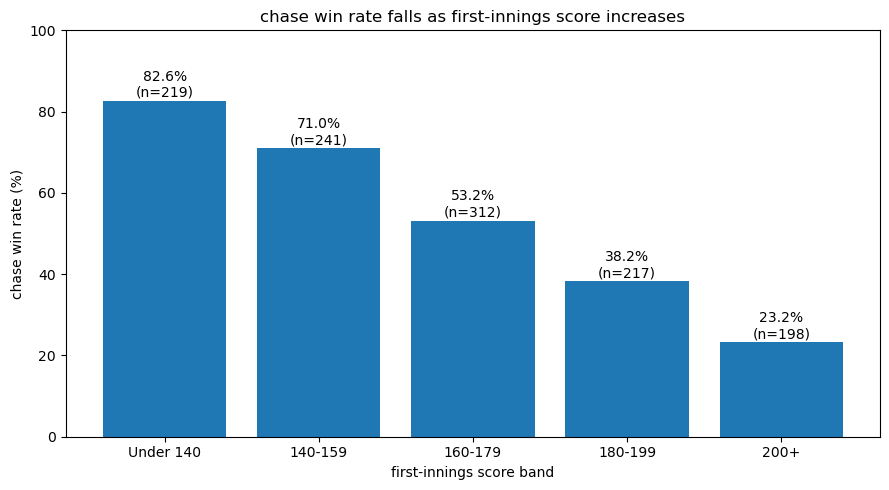

<Figure size 640x480 with 0 Axes>

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

bars=plt.bar(chase_bands['score_band'],
             chase_bands['chase_win_rate'])

plt.title('chase win rate falls as first-innings score increases')

plt.xlabel('first-innings score band')

plt.ylabel('chase win rate (%)')

for bar,rate,n in zip(
    bars,
    chase_bands['chase_win_rate'],
    chase_bands['sample_size']):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height()+1,
        f'{rate}%\n(n={n})',
        ha='center'
    )

plt.ylim(0,100)

plt.tight_layout()

plt.show()

plt.savefig("../reports/figures/chase_win_rate.png", dpi=300, bbox_inches="tight")


## Finding

The analysis shows that the chase win rate decreases as the first-innings score increases. When the first-innings score is below 140, the chase win rate is 82.6%, but it drops to 23.2% when the score is 200 or more. This indicates that chasing becomes more challenging as the target increases, putting greater pressure on the batting team.

## Business Action

Teams batting first should aim to set a competitive total based on the pitch conditions and match situation. A higher score can put pressure on the chasing team and improve the chances of winning. Teams chasing should plan their batting strategy according to the target, manage wickets carefully, and maintain a steady scoring rate. Franchises can use these insights to analyse match trends, improve strategies, and make data-driven decisions.
```
